# SRCNN — SEMICON 2× Super-Resolution Benchmark

This is a self-contained Kaggle benchmark using the manifest-defined SEMICON protocol. It never creates new splits. The model is **Bicubic pre-upsampling followed by three convolutional feature extraction and reconstruction layers.**

### Model diagram

`Input → shallow features → model-specific restoration trunk → reconstruction head → output`

For SR, reconstruction performs learned PixelShuffle ×2 (SRCNN uses its canonical bicubic pre-upsampling). For denoising, spatial dimensions remain unchanged. Validation and test inference use overlapping tiles to control VRAM.

### SEMICON suitability

- **Strengths:** Simple, reproducible and fast baseline.
- **Weaknesses:** Limited capacity and lower detail recovery ceiling.
- Estimated Kaggle P100/T4 runtime: **5–9 h** (full validation every epoch; actual runtime varies).
- Estimated peak VRAM: **3–6 GB**.


## 1. Environment and reproducibility

In [1]:
from __future__ import annotations
import csv, gc, json, math, os, random, subprocess, sys, time
from collections import defaultdict
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

try:
    import pyiqa
except ImportError:
    print("Installing canonical IQA implementations (NIQE, BRISQUE, PIQE, FSIM)...")
    subprocess.check_call([sys.executable,"-m","pip","install","-q","pyiqa"])
    import pyiqa

SEED=2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark=True
torch.backends.cudnn.deterministic=False
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP=DEVICE.type=="cuda"
print("PyTorch:",torch.__version__,"| device:",DEVICE)
if AMP: print(torch.cuda.get_device_name(0),"|",round(torch.cuda.get_device_properties(0).total_memory/2**30,1),"GiB")


Installing canonical IQA implementations (NIQE, BRISQUE, PIQE, FSIM)...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 12.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 84.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 MB 44.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.6/59.6 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.2/226.2 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.4/99.4 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 100.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 470.6/470.6 kB

## 2. Hyperparameters

| Setting | Value |
|---|---:|
| Task | sr |
| Epoch target | 300 |
| Training crop | 128 px on the input grid |
| Batch size | 16 |
| Optimizer | AdamW |
| Initial learning rate | 0.0001 |
| Scheduler | CosineAnnealingLR |
| AMP | Enabled on CUDA |
| Gradient clipping | 1.0 |
| Early-stopping patience | 60 epochs |
| Selection criterion | Validation PSNR |
| Validation frequency | Every epoch, complete manifest validation split |


In [2]:
MODEL_NAME="SRCNN"
TASK="sr"
EPOCHS=300
CROP_SIZE=128
BATCH_SIZE=16             # already 16 - SRCNN is a shallow 3-layer CNN, plenty of headroom to go higher (32+) if you want to test
LR=0.0001
IS_GAN=False
GAN_WEIGHT=0.005
PATIENCE=20                # counts VALIDATION CHECKS without improvement, not raw epochs (see VALIDATE_EVERY)
MIN_DELTA=0.005
WORKERS=min(4,os.cpu_count() or 1)
TILE=192
RESUME=True
VALIDATE_EVERY=3           # only run full validation every N epochs (always runs on epoch 1 and the final epoch)
USE_TORCH_COMPILE=True     # try torch.compile for a speedup; skipped automatically on unsupported GPUs (e.g. P100), falls back cleanly otherwise
print(dict(model=MODEL_NAME,task=TASK,epochs=EPOCHS,crop=CROP_SIZE,batch=BATCH_SIZE,lr=LR,gan=IS_GAN,validate_every=VALIDATE_EVERY))

{'model': 'SRCNN', 'task': 'sr', 'epochs': 300, 'crop': 128, 'batch': 16, 'lr': 0.0001, 'gan': False, 'validate_every': 3}


## 3. Manifest-defined dataset and paired loaders

Training uses paired random crops with aligned flips and rotations. Validation and test use the original images and manifest identities without augmentation. No image is reassigned to another split.

In [3]:
INPUT_ROOT=Path("/kaggle/input")
RUN_ROOT=Path("/kaggle/working")/MODEL_NAME
RUN_ROOT.mkdir(parents=True,exist_ok=True)

def records_from(payload):
    if isinstance(payload,list): return payload
    if isinstance(payload,dict) and isinstance(payload.get("samples"),list): return payload["samples"]
    raise ValueError("Unsupported manifest schema")

def locate_dataset():
    candidates=[]
    for p in INPUT_ROOT.rglob("manifest.json"):
        try:
            payload=json.loads(p.read_text(encoding="utf-8")); rows=records_from(payload)
            text=p.as_posix().lower(); score=len(rows)
            if TASK=="denoise": score+=100000*int("noise" in text)-100000*int("sr_2x" in text)
            else: score+=100000*int("sr_2x" in text)-100000*int("noise" in text)
            candidates.append((score,p,payload,rows))
        except Exception: pass
    if not candidates: raise FileNotFoundError("Compatible manifest.json not found under /kaggle/input")
    _,p,payload,rows=max(candidates,key=lambda x:x[0]); return p.parent,p,payload,rows

ROOT,MANIFEST,PAYLOAD,RECORDS=locate_dataset()
def norm_split(x):
    x=str(x).lower(); return "val" if x in {"validation","valid"} else x
SPLITS={s:[r for r in RECORDS if norm_split(r.get("split"))==s] for s in ("train","val","test")}
print("Dataset:",ROOT,"| manifest:",MANIFEST)
print({k:len(v) for k,v in SPLITS.items()})
assert all(SPLITS.values()),"Manifest must define non-empty train/val/test splits"

def resolve(value):
    p=Path(str(value))
    if p.is_absolute() and p.is_file(): return p
    q=ROOT/p
    if q.is_file(): return q
    hits=list(ROOT.rglob(p.name))
    if len(hits)==1:return hits[0]
    raise FileNotFoundError(value)

def pair_paths(r):
    hr=resolve(r.get("hr_path") or r.get("HR path"))
    lr=resolve(r.get("lr_path") or r.get("LR path"))
    return lr,hr

class PairedDataset(Dataset):
    def __init__(self,rows,training=False): self.rows=rows; self.training=training
    def __len__(self): return len(self.rows)
    def __getitem__(self,index):
        r=self.rows[index]; lp,hp=pair_paths(r)
        lr=np.asarray(Image.open(lp).convert("L"),dtype=np.float32)/255.
        hr=np.asarray(Image.open(hp).convert("L"),dtype=np.float32)/255.
        if self.training:
            rng=np.random.default_rng(SEED+index+torch.initial_seed()%100000)
            if TASK=="sr":
                c=min(CROP_SIZE,lr.shape[0],lr.shape[1]); y=int(rng.integers(0,lr.shape[0]-c+1)); x=int(rng.integers(0,lr.shape[1]-c+1))
                lr=lr[y:y+c,x:x+c]; hr=hr[2*y:2*(y+c),2*x:2*(x+c)]
            else:
                c=min(CROP_SIZE,lr.shape[0],lr.shape[1]); y=int(rng.integers(0,lr.shape[0]-c+1)); x=int(rng.integers(0,lr.shape[1]-c+1))
                lr=lr[y:y+c,x:x+c]; hr=hr[y:y+c,x:x+c]
            if rng.random()<.5: lr=np.fliplr(lr); hr=np.fliplr(hr)
            if rng.random()<.5: lr=np.flipud(lr); hr=np.flipud(hr)
            k=int(rng.integers(0,4)); lr=np.rot90(lr,k); hr=np.rot90(hr,k)
        return {"lr":torch.from_numpy(np.ascontiguousarray(lr))[None],"hr":torch.from_numpy(np.ascontiguousarray(hr))[None],"id":str(r.get("sample_id",index))}

def worker_seed(worker_id):
    seed=SEED+worker_id; random.seed(seed); np.random.seed(seed)
g=torch.Generator().manual_seed(SEED)
train_loader=DataLoader(PairedDataset(SPLITS["train"],True),batch_size=BATCH_SIZE,shuffle=True,num_workers=WORKERS,pin_memory=AMP,persistent_workers=WORKERS>0,worker_init_fn=worker_seed,generator=g,drop_last=True)
val_loader=DataLoader(PairedDataset(SPLITS["val"]),batch_size=1,shuffle=False,num_workers=WORKERS,pin_memory=AMP,persistent_workers=WORKERS>0)
test_loader=DataLoader(PairedDataset(SPLITS["test"]),batch_size=1,shuffle=False,num_workers=WORKERS,pin_memory=AMP,persistent_workers=WORKERS>0)
batch=next(iter(train_loader)); print("Training batch LR/HR:",batch["lr"].shape,batch["hr"].shape)


Dataset: /kaggle/input/datasets/omkadam05/semicon-v2-dual-dataset/SEMICON_SR_2X_v2/SEMICON_SR_2X_v2 | manifest: /kaggle/input/datasets/omkadam05/semicon-v2-dual-dataset/SEMICON_SR_2X_v2/SEMICON_SR_2X_v2/manifest.json
{'train': 2910, 'val': 831, 'test': 417}
Training batch LR/HR: torch.Size([16, 1, 128, 128]) torch.Size([16, 1, 256, 256])


## 4. Architecture implementation

The following cell contains the complete model definition used by this notebook. It is deliberately local to the notebook so checkpoint reconstruction does not depend on a cloned repository.

In [4]:
class ResBlock(nn.Module):
 def __init__(self,c,scale=1.): super().__init__(); self.body=nn.Sequential(nn.Conv2d(c,c,3,1,1),nn.ReLU(True),nn.Conv2d(c,c,3,1,1)); self.scale=scale
 def forward(self,x): return x+self.body(x)*self.scale
class CALayer(nn.Module):
 def __init__(self,c,r=8): super().__init__(); self.m=nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Conv2d(c,max(4,c//r),1),nn.ReLU(True),nn.Conv2d(max(4,c//r),c,1),nn.Sigmoid())
 def forward(self,x): return x*self.m(x)
class CAB(nn.Module):
 def __init__(self,c): super().__init__(); self.m=nn.Sequential(nn.Conv2d(c,c,3,1,1),nn.GELU(),nn.Conv2d(c,c,3,1,1),CALayer(c))
 def forward(self,x): return x+self.m(x)
class LayerNorm2d(nn.Module):
 def __init__(self,c): super().__init__(); self.w=nn.Parameter(torch.ones(1,c,1,1)); self.b=nn.Parameter(torch.zeros(1,c,1,1))
 def forward(self,x):
  v=x.var(1,keepdim=True,unbiased=False); m=x.mean(1,keepdim=True); return (x-m)/torch.sqrt(v+1e-5)*self.w+self.b

class Model(nn.Module):
 def __init__(self): super().__init__(); self.net=nn.Sequential(nn.Conv2d(1,64,9,1,4),nn.ReLU(True),nn.Conv2d(64,32,5,1,2),nn.ReLU(True),nn.Conv2d(32,1,5,1,2))
 def forward(self,x): return self.net(F.interpolate(x,scale_factor=2,mode="bicubic",align_corners=False))

## 5. Training, validation, checkpointing and resume

Each epoch performs AMP training, gradient clipping, cosine scheduling, complete validation, CSV history export, best-PSNR checkpointing, last-state checkpointing and patience-based stopping. Setting `RESUME=True` restores the last optimizer, scheduler and scaler states.

In [5]:
model=Model().to(DEVICE)
if USE_TORCH_COMPILE and DEVICE.type=="cuda":
    _major,_minor=torch.cuda.get_device_capability(0)
    if _major<7:
        print(f"Skipping torch.compile - GPU capability sm_{_major}{_minor} is below sm_70, "
              f"which this PyTorch build's compiled kernels require (e.g. P100). "
              f"Switch to a T4/A100/etc. to use torch.compile, or leave it off on this GPU.")
    else:
        try:
            model=torch.compile(model)
            print("torch.compile enabled")
        except Exception as e:
            print("torch.compile unavailable/failed, continuing without it:",e)
discriminator=Discriminator().to(DEVICE) if IS_GAN else None
print("Trainable parameters:",sum(p.numel() for p in model.parameters() if p.requires_grad))
optimizer=torch.optim.AdamW(model.parameters(),lr=LR,betas=(.9,.99),weight_decay=1e-4)
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=EPOCHS,eta_min=LR*0.01)
if IS_GAN:
 d_optimizer=torch.optim.AdamW(discriminator.parameters(),lr=LR,betas=(.9,.99),weight_decay=1e-4)
 d_scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(d_optimizer,T_max=EPOCHS,eta_min=LR*.01)
scaler=torch.amp.GradScaler("cuda",enabled=AMP)

def structural_loss(pred,target):
 gx=lambda z:z[:,:,:,1:]-z[:,:,:,:-1]; gy=lambda z:z[:,:,1:,:]-z[:,:,:-1,:]
 return F.l1_loss(gx(pred),gx(target))+F.l1_loss(gy(pred),gy(target))
def d_outputs(d,x):
 y=d(x)
 if isinstance(y,list): return [v[-1] if isinstance(v,list) else v for v in y]
 return [y]
def generator_loss(pred,hr,lr):
 rec=F.l1_loss(pred,hr)+.1*structural_loss(pred,hr)
 if not IS_GAN:return rec,{"reconstruction":float(rec.detach())}
 src=F.interpolate(lr,size=hr.shape[-2:],mode="bicubic",align_corners=False) if TASK=="sr" else lr
 fake=d_outputs(discriminator,torch.cat([src,pred],1)); adv=sum(F.binary_cross_entropy_with_logits(v,torch.ones_like(v)) for v in fake)/len(fake)
 total=rec+GAN_WEIGHT*adv; return total,{"reconstruction":float(rec.detach()),"adversarial":float(adv.detach())}

def metric_batch(pred,hr):
 pred=pred.clamp(0,1); mse=((pred-hr)**2).flatten(1).mean(1); mae=(pred-hr).abs().flatten(1).mean(1)
 psnr=-10*torch.log10(mse.clamp_min(1e-12));
 # Global SSIM is stable and efficient for epoch-level model selection.
 ux=pred.flatten(1).mean(1); uy=hr.flatten(1).mean(1); vx=pred.flatten(1).var(1,unbiased=False); vy=hr.flatten(1).var(1,unbiased=False); cov=((pred-ux[:,None,None,None])*(hr-uy[:,None,None,None])).flatten(1).mean(1)
 ssim=((2*ux*uy+.01**2)*(2*cov+.03**2))/((ux**2+uy**2+.01**2)*(vx+vy+.03**2))
 return psnr.mean().item(),ssim.mean().item(),mae.mean().item(),mse.mean().item()

@torch.inference_mode()
def tiled_forward(x,tile=TILE,overlap=32):
 scale=2 if TASK=="sr" else 1; b,c,h,w=x.shape
 if h<=tile and w<=tile:return model(x)
 out=torch.zeros((b,1,h*scale,w*scale),device=x.device); weight=torch.zeros_like(out); step=tile-overlap
 ys=list(range(0,max(1,h-tile+1),step)); xs=list(range(0,max(1,w-tile+1),step))
 if not ys or ys[-1]!=h-tile:ys.append(max(0,h-tile))
 if not xs or xs[-1]!=w-tile:xs.append(max(0,w-tile))
 for y in ys:
  for z in xs:
   patch=x[:,:,y:y+tile,z:z+tile]; p=model(patch); out[:,:,y*scale:(y+patch.shape[-2])*scale,z*scale:(z+patch.shape[-1])*scale]+=p; weight[:,:,y*scale:(y+patch.shape[-2])*scale,z*scale:(z+patch.shape[-1])*scale]+=1
 return out/weight.clamp_min(1)

@torch.inference_mode()
def validate(loader):
 model.eval(); sums=np.zeros(5); n=0
 for batch in tqdm(loader,leave=False,desc="validation"):
  lr=batch["lr"].to(DEVICE,non_blocking=True); hr=batch["hr"].to(DEVICE,non_blocking=True)
  with torch.amp.autocast("cuda",enabled=AMP): pred=tiled_forward(lr); loss=F.l1_loss(pred,hr)
  p,s,a,m=metric_batch(pred.float(),hr); sums+=np.array([loss.item(),p,s,a,m]); n+=1
 return dict(zip(["val_loss","psnr","ssim","mae","mse"],sums/max(n,1)))

best=-float("inf"); patience_count=0; history=[]; start_epoch=1
last_path=RUN_ROOT/"last_checkpoint.pth"; best_path=RUN_ROOT/"best_checkpoint.pth"
if RESUME and last_path.is_file():
 ck=torch.load(last_path,map_location=DEVICE,weights_only=False); model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"]); history=ck["history"]; best=ck["best"]; patience_count=ck["patience_count"]; start_epoch=ck["epoch"]+1
 if IS_GAN: discriminator.load_state_dict(ck["discriminator"]); d_optimizer.load_state_dict(ck["d_optimizer"]); d_scheduler.load_state_dict(ck["d_scheduler"])
 print("Resumed at epoch",start_epoch)

for epoch in range(start_epoch,EPOCHS+1):
 model.train(); discriminator.train() if IS_GAN else None; total=0.; seen=0
 bar=tqdm(train_loader,desc=f"{MODEL_NAME} {epoch}/{EPOCHS}")
 for batch in bar:
  lr=batch["lr"].to(DEVICE,non_blocking=True); hr=batch["hr"].to(DEVICE,non_blocking=True)
  if IS_GAN:
   with torch.amp.autocast("cuda",enabled=AMP): fake=model(lr); src=F.interpolate(lr,size=hr.shape[-2:],mode="bicubic",align_corners=False) if TASK=="sr" else lr; real_o=d_outputs(discriminator,torch.cat([src,hr],1)); fake_o=d_outputs(discriminator,torch.cat([src,fake.detach()],1)); dl=sum(F.binary_cross_entropy_with_logits(a,torch.ones_like(a))+F.binary_cross_entropy_with_logits(b,torch.zeros_like(b)) for a,b in zip(real_o,fake_o))/(2*len(real_o))
   d_optimizer.zero_grad(set_to_none=True); scaler.scale(dl).backward(); scaler.unscale_(d_optimizer); nn.utils.clip_grad_norm_(discriminator.parameters(),1.0); scaler.step(d_optimizer)
  with torch.amp.autocast("cuda",enabled=AMP): pred=model(lr); loss,parts=generator_loss(pred,hr,lr)
  optimizer.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(optimizer); nn.utils.clip_grad_norm_(model.parameters(),1.0); scaler.step(optimizer); scaler.update()
  total+=loss.item()*lr.size(0); seen+=lr.size(0); bar.set_postfix(loss=f"{total/seen:.4f}")
 scheduler.step(); d_scheduler.step() if IS_GAN else None
 do_validate=(epoch==1) or (epoch%VALIDATE_EVERY==0) or (epoch==EPOCHS)
 if do_validate:
  metrics=validate(val_loader); row={"epoch":epoch,"train_loss":total/seen,"lr":optimizer.param_groups[0]["lr"],**metrics}; history.append(row); pd.DataFrame(history).to_csv(RUN_ROOT/"training_history.csv",index=False)
  improved=metrics["psnr"]>best+MIN_DELTA
  if improved: best=metrics["psnr"]; patience_count=0; torch.save({"model":model.state_dict(),"epoch":epoch,"metrics":metrics},best_path)
  else: patience_count+=1
  print(row,"| patience",patience_count,"/",PATIENCE)
 else:
  print({"epoch":epoch,"train_loss":total/seen,"lr":optimizer.param_groups[0]["lr"]},"(validation skipped this epoch)")
 state={"epoch":epoch,"model":model.state_dict(),"optimizer":optimizer.state_dict(),"scheduler":scheduler.state_dict(),"scaler":scaler.state_dict(),"history":history,"best":best,"patience_count":patience_count}
 if IS_GAN: state.update(discriminator=discriminator.state_dict(),d_optimizer=d_optimizer.state_dict(),d_scheduler=d_scheduler.state_dict())
 torch.save(state,last_path)
 if do_validate and patience_count>=PATIENCE: print("Early stopping"); break


torch.compile enabled
Trainable parameters: 57281


SRCNN 1/300:   0%|          | 0/181 [00:00<?, ?it/s]

W0812 13:45:06.790000 22 torch/_inductor/utils.py:1679] [0/0] Not enough SMs to use max_autotune_gemm mode


validation:   0%|          | 0/831 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.07459745216517817, 'lr': 9.999728588359285e-05, 'val_loss': np.float64(0.043399348878553845), 'psnr': np.float64(23.777097730716932), 'ssim': np.float64(0.9527115796734136), 'mae': np.float64(0.04305270185333225), 'mse': np.float64(0.004796846317222329)} | patience 0 / 20


...

SRCNN 299/300:   0%|          | 0/181 [00:00<?, ?it/s]

{'epoch': 299, 'train_loss': 0.041122770533788926, 'lr': 1.0027141164071492e-06} (validation skipped this epoch)


SRCNN 300/300:   0%|          | 0/181 [00:00<?, ?it/s]

validation:   0%|          | 0/831 [00:00<?, ?it/s]

{'epoch': 300, 'train_loss': 0.041242904292203446, 'lr': 1.0000000000000002e-06, 'val_loss': np.float64(0.030801507844404732), 'psnr': np.float64(26.094011491529923), 'ssim': np.float64(0.9694510023372985), 'mae': np.float64(0.030701662487183416), 'mse': np.float64(0.003124284142752012)} | patience 14 / 20


## 6. Final best-checkpoint evaluation and reporting

Only the best validation-PSNR generator is evaluated on the test split. Canonical NIQE, BRISQUE, PIQE and FSIM are computed through `pyiqa`; installation requires Kaggle Internet on the first run. No nonstandard proxy is silently substituted.

Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/niqe_modelparameters.mat" to /root/.cache/torch/hub/pyiqa/niqe_modelparameters.mat



100%|██████████| 8.15k/8.15k [00:00<00:00, 13.4MB/s]

Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/brisque_svm_weights.pth" to /root/.cache/torch/hub/pyiqa/brisque_svm_weights.pth




100%|██████████| 112k/112k [00:00<00:00, 342kB/s]


final test:   0%|          | 0/417 [00:00<?, ?it/s]

,model,parameters,inference_time_s,fps,peak_gpu_memory_gib,psnr,ssim,mae,mse,rmse,niqe,brisque,piqe,entropy,fsim
0,SRCNN,57281,0.023787,42.039122,0.116285,26.115722,0.969699,0.030756,0.003167,0.05259,6.910212,45.4815,26.116614,6.245269,0.985839


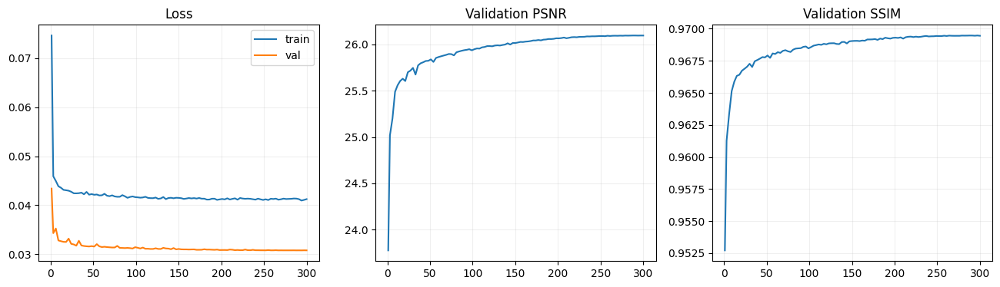

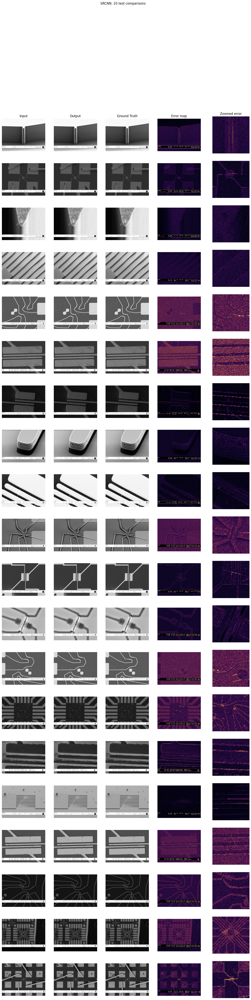

All outputs: /kaggle/working/SRCNN


In [6]:
checkpoint=torch.load(best_path,map_location=DEVICE,weights_only=False); model.load_state_dict(checkpoint["model"]); model.eval()

available=set(pyiqa.list_models())
required={"niqe":"niqe","brisque":"brisque","piqe":"piqe","fsim":"fsim"}
missing=[v for v in required.values() if v not in available]
if missing: raise RuntimeError(f"Installed pyiqa lacks required canonical metrics: {missing}. Do not substitute proxy scores.")
iqa={k:pyiqa.create_metric(v,device=DEVICE) for k,v in required.items()}

def entropy_score(x):
 a=(x.clamp(0,1)*255).byte().cpu().numpy().ravel(); h=np.bincount(a,minlength=256).astype(float); p=h[h>0]/h.size if False else h[h>0]/h.sum(); return float(-(p*np.log2(p)).sum())

rows=[]; inference=[]; peak=0
if AMP: torch.cuda.reset_peak_memory_stats()
with torch.inference_mode():
 for batch in tqdm(test_loader,desc="final test"):
  lr=batch["lr"].to(DEVICE,non_blocking=True); hr=batch["hr"].to(DEVICE,non_blocking=True)
  if AMP: torch.cuda.synchronize()
  t=time.perf_counter()
  with torch.amp.autocast("cuda",enabled=AMP): pred=tiled_forward(lr).clamp(0,1)
  if AMP: torch.cuda.synchronize()
  inference.append(time.perf_counter()-t); p,s,a,m=metric_batch(pred.float(),hr); rm=math.sqrt(m)
  # IQA models expect RGB. Replication preserves grayscale information.
  pr=pred.repeat(1,3,1,1); gt=hr.repeat(1,3,1,1)
  vals={}
  for name,metric in iqa.items():
   vals[name]=float(metric(pr,gt).mean()) if name=="fsim" else float(metric(pr).mean())
  rows.append({"sample_id":batch["id"][0],"psnr":p,"ssim":s,"mae":a,"mse":m,"rmse":rm,"entropy":entropy_score(pred),**vals})

per_image=pd.DataFrame(rows); per_image.to_csv(RUN_ROOT/"test_per_image_metrics.csv",index=False)
summary={"model":MODEL_NAME,"parameters":sum(p.numel() for p in model.parameters()),"inference_time_s":float(np.mean(inference)),"fps":float(1/np.mean(inference)),"peak_gpu_memory_gib":float(torch.cuda.max_memory_allocated()/2**30) if AMP else 0.0}
for c in ["psnr","ssim","mae","mse","rmse","niqe","brisque","piqe","entropy","fsim"]: summary[c]=float(per_image[c].mean())
pd.DataFrame([summary]).to_csv(RUN_ROOT/"results.csv",index=False); display(pd.DataFrame([summary]))

h=pd.DataFrame(history); fig,ax=plt.subplots(1,3,figsize=(16,4)); ax[0].plot(h.epoch,h.train_loss,label="train"); ax[0].plot(h.epoch,h.val_loss,label="val"); ax[0].legend(); ax[0].set_title("Loss"); ax[1].plot(h.epoch,h.psnr); ax[1].set_title("Validation PSNR"); ax[2].plot(h.epoch,h.ssim); ax[2].set_title("Validation SSIM"); [a.grid(alpha=.2) for a in ax]; fig.savefig(RUN_ROOT/"training_curves.png",dpi=180,bbox_inches="tight"); plt.show()

@torch.inference_mode()
def visual_examples(count=20):
 picks=np.random.default_rng(SEED).choice(len(SPLITS["test"]),count,replace=False); fig,axes=plt.subplots(count,5,figsize=(17,3*count))
 ds=PairedDataset(SPLITS["test"])
 for row,idx in enumerate(picks):
  b=ds[int(idx)]; x=b["lr"][None].to(DEVICE); hr=b["hr"][None].to(DEVICE); pred=tiled_forward(x).clamp(0,1); shown=F.interpolate(x,size=hr.shape[-2:],mode="bicubic",align_corners=False)
  a=hr[0,0].cpu().numpy(); z=pred[0,0].cpu().numpy(); inp=shown[0,0].cpu().numpy(); diff=np.abs(z-a); y=(a.shape[0]-256)//2; q=(a.shape[1]-256)//2
  arrays=[inp,z,a,diff,diff[y:y+256,q:q+256]]; titles=["Input","Output","Ground Truth","Error map","Zoomed error"]
  for col,(arr,title) in enumerate(zip(arrays,titles)): axes[row,col].imshow(arr,cmap="inferno" if col>=3 else "gray",vmin=0,vmax=.2 if col>=3 else 1); axes[row,col].axis("off"); axes[row,col].set_title(title if row==0 else "")
 fig.suptitle(f"{MODEL_NAME}: 20 test comparisons"); fig.savefig(RUN_ROOT/"test_visual_comparisons.png",dpi=150,bbox_inches="tight"); plt.show()
visual_examples()
print("All outputs:",RUN_ROOT)


## 7. Benchmark interpretation

The exported `results.csv` is the single-row benchmark summary; `test_per_image_metrics.csv` contains every test image. Model selection uses validation PSNR, while the final report includes distortion, perceptual/no-reference, efficiency and memory measurements. For semiconductor inspection, always inspect error maps before accepting a perceptually sharper GAN result because hallucinated edges can be harmful.
